# Cohort Analysis — monthly attendance retention

**Question:** of the members who joined in a given month, what share attended an event in each of the following months?

**Definitions**
- **Cohort:** the year-month in which a member joined the group (`Joined Group on`, from `group_members.csv`).
- **Cohort size:** every member who joined in that month, including members who never attended anything.
- **M0, M1, M2, …:** months since joining. M0 is the join month itself, M1 the next calendar month, and so on.
- **Attended:** the member has an RSVP of `YES` for an event in that month (`group_attendance.csv`), excluding rows marked `EXCUSED_ABSENCE` or `NO_SHOW`. Meetup almost never records actual attendance (95% `UNKNOWN`), so a YES RSVP is the proxy. The EDA found that about 93% of YES RSVPs turn into attendance.
- **Cell value:** % of the cohort who attended **at least one event in that specific month**. This is monthly activity, not cumulative, so values can go up and down.
- **Scope:** per-event data starts in **2024-11**, so only cohorts from 2024-11 onward are included. That way every cell is fully observed. Cells after the last month in the data are left empty.

## 1. Setup & load

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="white", context="notebook")
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)

DATA_DIR = Path("../data")
FIRST_COHORT = pd.Period("2024-11", freq="M")

# Only the columns we need: names and profile URLs are never loaded
members = pd.read_csv(DATA_DIR / "group_members.csv", usecols=["Member ID", "Joined Group on"])
members["joined"] = pd.to_datetime(members["Joined Group on"], format="%B %d, %Y")

att = pd.read_csv(DATA_DIR / "group_attendance.csv",
                  usecols=["Member ID", "Event ID", "Event Local Date and Time", "RSVP Status", "Attendance Status"])
att["event_dt"] = pd.to_datetime(att["Event Local Date and Time"], format="%B %d, %Y %H:%M")

PRESENT = max(members["joined"].max(), att["event_dt"].max()).to_period("M")
print(f"Members: {len(members):,} | attendance rows: {len(att):,} | events: {att['Event ID'].nunique()}")
print(f"First event in data: {att['event_dt'].min().date()} | present (last month in data): {PRESENT}")

Members: 1,620 | attendance rows: 998 | events: 36
First event in data: 2024-11-07 | present (last month in data): 2026-10


## 2. Build cohorts and monthly activity

In [2]:
members["cohort"] = members["joined"].dt.to_period("M")
cohort_members = members[members["cohort"] >= FIRST_COHORT]
cohort_size = cohort_members.groupby("cohort").size().rename("size")
cohort_size = cohort_size.reindex(pd.period_range(FIRST_COHORT, PRESENT, freq="M"), fill_value=0)
print(f"Members in scope (joined {FIRST_COHORT} .. {PRESENT}): {len(cohort_members):,} in {len(cohort_size)} cohorts")

attended = att[(att["RSVP Status"] == "YES") & ~att["Attendance Status"].isin(["EXCUSED_ABSENCE", "NO_SHOW"])].copy()
attended["activity_month"] = attended["event_dt"].dt.to_period("M")
print(f"Attendance rows (YES, not excused / no-show): {len(attended):,} of {len(att):,}")

activity = attended.merge(cohort_members[["Member ID", "cohort"]], on="Member ID", how="inner")
activity["month_index"] = (activity["activity_month"] - activity["cohort"]).apply(lambda d: d.n)

negative = activity[activity["month_index"] < 0]
print(f"Dropped {len(negative)} attendance rows dated before the member's (re)join month "
      f"({negative['Member ID'].nunique()} members, most likely members who left and rejoined)")
activity = activity[activity["month_index"] >= 0]

Members in scope (joined 2024-11 .. 2026-10): 850 in 24 cohorts
Attendance rows (YES, not excused / no-show): 683 of 998
Dropped 1 attendance rows dated before the member's (re)join month (1 members, most likely members who left and rejoined)


## 3. Cohort matrix

In [3]:
counts = (activity.pivot_table(index="cohort", columns="month_index", values="Member ID", aggfunc="nunique")
          .reindex(index=cohort_size.index, columns=range(len(cohort_size))))

# Cells that are observable (cohort + k <= PRESENT) and had no activity are 0; cells in the future stay NaN
observable = np.array([[c + k <= PRESENT for k in counts.columns] for c in counts.index])
counts = counts.fillna(0).where(observable)

pct = counts.div(cohort_size.replace(0, np.nan), axis=0) * 100
pct = pct.sort_index()  # ascending by cohort (activation) month
counts = counts.sort_index()

pct.columns = [f"M{k}" for k in pct.columns]
counts.columns = [f"M{k}" for k in counts.columns]
pct.index = pct.index.astype(str); counts.index = counts.index.astype(str)
pct.index.name = counts.index.name = "cohort"

### 3.1 Cohort matrix — % of cohort attending in month *k* after joining

In [4]:
cohort_matrix = pct.round(1).astype(object).where(pct.notna(), "")
cohort_matrix.insert(0, "size", cohort_size.values)
print(cohort_matrix.to_string())

         size    M0     M1    M2   M3    M4   M5   M6   M7   M8   M9  M10   M11   M12  M13  M14  M15  M16   M17  M18  M19  M20  M21  M22  M23
cohort                                                                                                                                       
2024-11    19  15.8   31.6   0.0  0.0   0.0  0.0  5.3  0.0  0.0  0.0  0.0   0.0  10.5  5.3  5.3  5.3  5.3   0.0  5.3  5.3  0.0  0.0  0.0  0.0
2024-12    16  25.0    6.2   0.0  6.2   0.0  0.0  0.0  6.2  0.0  0.0  0.0   0.0   6.2  6.2  6.2  6.2  0.0   0.0  0.0  6.2  0.0  0.0  0.0     
2025-01    24   4.2    4.2   0.0  4.2   0.0  4.2  0.0  0.0  0.0  0.0  0.0   0.0   0.0  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0  4.2          
2025-02    19   0.0    0.0   0.0  0.0   5.3  0.0  0.0  0.0  5.3  5.3  0.0   0.0   0.0  0.0  0.0  0.0  0.0   0.0  0.0  5.3  5.3               
2025-03    17   0.0   11.8  17.6  5.9   5.9  0.0  0.0  5.9  0.0  0.0  0.0  11.8   5.9  5.9  5.9  5.9  5.9  17.6  5.9  0.0                    
2025-0

### 3.2 Cohort matrix — number of members attending (counts)

In [5]:
count_matrix = counts.astype("Int64").astype(object).where(counts.notna(), "")
count_matrix.insert(0, "size", cohort_size.values)
print(count_matrix.to_string())

         size  M0  M1 M2 M3 M4 M5 M6 M7 M8 M9 M10 M11 M12 M13 M14 M15 M16 M17 M18 M19 M20 M21 M22 M23
cohort                                                                                               
2024-11    19   3   6  0  0  0  0  1  0  0  0   0   0   2   1   1   1   1   0   1   1   0   0   0   0
2024-12    16   4   1  0  1  0  0  0  1  0  0   0   0   1   1   1   1   0   0   0   1   0   0   0    
2025-01    24   1   1  0  1  0  1  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   1        
2025-02    19   0   0  0  0  1  0  0  0  1  1   0   0   0   0   0   0   0   0   0   1   1            
2025-03    17   0   2  3  1  1  0  0  1  0  0   0   2   1   1   1   1   1   3   1   0                
2025-04    31   2   7  1  0  1  0  0  1  1  1   1   0   1   1   1   1   2   2   0                    
2025-05    60  13   4  1  2  2  3  1  1  1  2   1   2   0   0   1   1   0   1                        
2025-06    36   3   3  0  0  1  1  1  0  2  1   3   1   0   0   2   2   1         

In [6]:
# Sanity checks
assert cohort_size.sum() == (members["joined"] >= FIRST_COHORT.start_time).sum()
vals = pct.stack().dropna()  # pandas 3 keeps NaN in stack()
assert vals.between(0, 100).all(), vals[~vals.between(0, 100)]
assert pct.iloc[-1].notna().sum() == 1, "latest cohort should only have M0"
assert list(pct.index) == sorted(pct.index)
check_cohort = "2025-05"
manual = activity[(activity["cohort"] == pd.Period(check_cohort, "M")) & (activity["month_index"] == 0)]["Member ID"].nunique()
assert manual == counts.loc[check_cohort, "M0"]
print(f"All checks passed (e.g. {check_cohort} M0: {manual} of {cohort_size[pd.Period(check_cohort, 'M')]} members)")

All checks passed (e.g. 2025-05 M0: 13 of 60 members)


## 4. Visuals

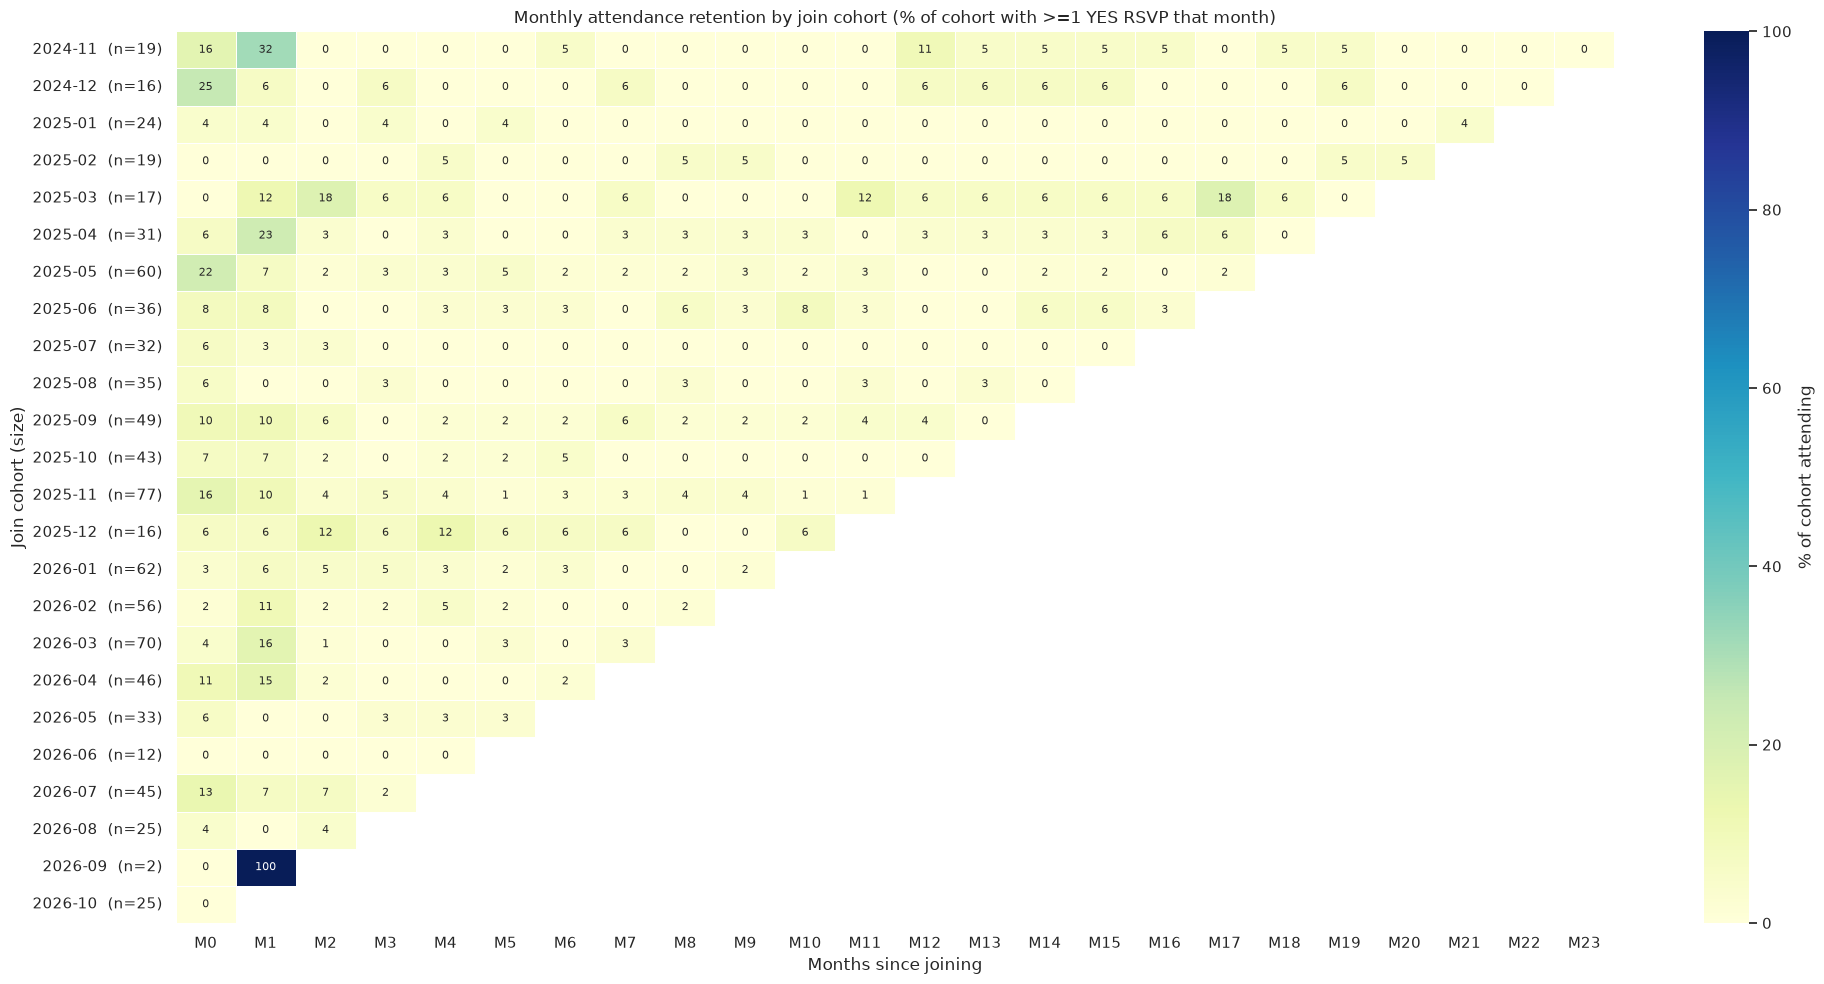

In [7]:
fig, ax = plt.subplots(figsize=(20, 10))
sns.heatmap(pct, annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={"label": "% of cohort attending"},
            linewidths=0.4, linecolor="white", ax=ax, annot_kws={"size": 8})
ax.set_yticklabels([f"{c}  (n={n})" for c, n in zip(pct.index, cohort_size.values)], rotation=0)
ax.set_xlabel("Months since joining"); ax.set_ylabel("Join cohort (size)")
ax.set_title("Monthly attendance retention by join cohort (% of cohort with >=1 YES RSVP that month)")
plt.tight_layout(); plt.show()

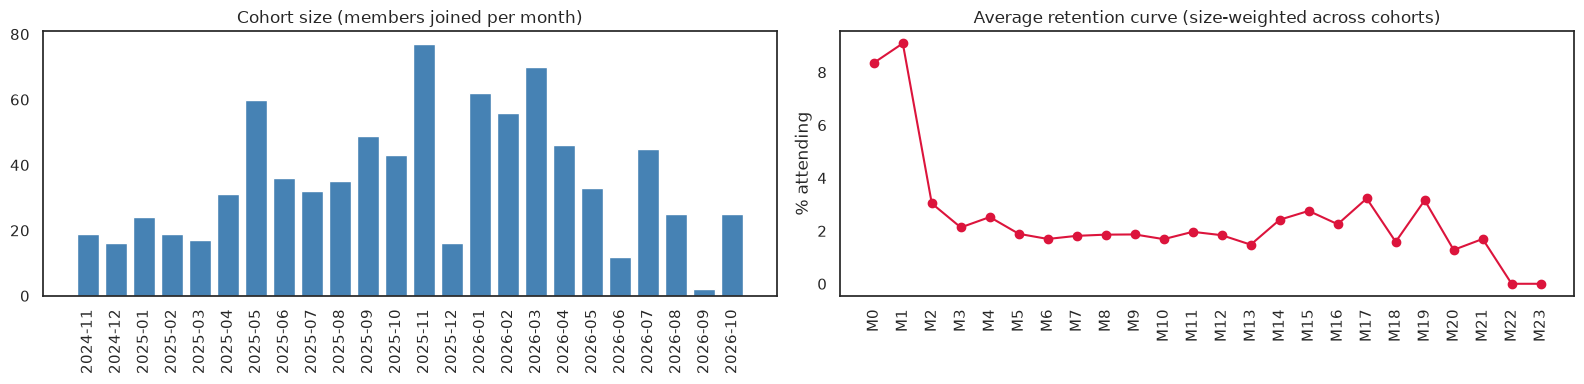

                    M0    M1    M2    M3    M4    M5    M6    M7    M8    M9   M10   M11   M12   M13   M14  M15  M16  M17  M18  M19  M20  M21  M22  M23
weighted_%         8.4   9.1   3.0   2.1   2.5   1.9   1.7   1.8   1.9   1.9   1.7   2.0   1.8   1.5   2.4  2.8  2.3  3.2  1.6  3.2  1.3  1.7  0.0  0.0
cohorts_observed  24.0  23.0  22.0  21.0  20.0  19.0  18.0  17.0  16.0  15.0  14.0  13.0  12.0  11.0  10.0  9.0  8.0  7.0  6.0  5.0  4.0  3.0  2.0  1.0


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
axes[0].bar(cohort_size.index.astype(str), cohort_size.values, color="steelblue")
axes[0].set_title("Cohort size (members joined per month)"); axes[0].tick_params(axis="x", rotation=90)

# Size-weighted average over the cohorts that can observe each month index
weighted = counts.sum() / counts.notna().mul(cohort_size.values, axis=0).sum() * 100
n_cohorts = counts.notna().sum()
axes[1].plot(range(len(weighted)), weighted.values, marker="o", color="crimson")
axes[1].set_xticks(range(len(weighted)), weighted.index, rotation=90)
axes[1].set_title("Average retention curve (size-weighted across cohorts)"); axes[1].set_ylabel("% attending")
plt.tight_layout(); plt.show()

summary = pd.DataFrame({"weighted_%": weighted.round(1), "cohorts_observed": n_cohorts})
print(summary.T.to_string())

In [9]:
ever = activity.groupby("cohort")["Member ID"].nunique().reindex(cohort_size.index, fill_value=0)
m0_m1 = activity[activity["month_index"] <= 1].groupby("cohort")["Member ID"].nunique().reindex(cohort_size.index, fill_value=0)
per_cohort = pd.DataFrame({
    "size": cohort_size,
    "M0_%": pct["M0"].values,
    "attended_M0_or_M1_%": (m0_m1 / cohort_size * 100).round(1).values,
    "ever_attended_%": (ever / cohort_size * 100).round(1).values,
    "months_observed": counts.notna().sum(axis=1).values,
})
per_cohort.index = per_cohort.index.astype(str)
print("Activation summary per cohort:")
print(per_cohort.round(1).to_string())
print(f"\nOverall: {ever.sum()} of {cohort_size.sum()} members in scope ever attended ({ever.sum() / cohort_size.sum():.1%}); "
      f"M0 activation {counts['M0'].sum() / cohort_size.sum():.1%}")

Activation summary per cohort:
         size  M0_%  attended_M0_or_M1_%  ever_attended_%  months_observed
2024-11    19  15.8                 42.1             47.4               24
2024-12    16  25.0                 31.2             31.2               23
2025-01    24   4.2                  8.3             20.8               22
2025-02    19   0.0                  0.0             10.5               21
2025-03    17   0.0                 11.8             17.6               20
2025-04    31   6.5                 29.0             35.5               19
2025-05    60  21.7                 23.3             26.7               18
2025-06    36   8.3                 16.7             25.0               17
2025-07    32   6.2                  9.4              9.4               16
2025-08    35   5.7                  5.7             14.3               15
2025-09    49  10.2                 18.4             24.5               14
2025-10    43   7.0                 11.6             11.6            

## 5. Key findings

**Activation is low and mostly happens in the first two months**
- Of the **850 members** who joined between 2024-11 and 2026-10, only **171 (20.1%) attended at least one event** in the period.
- On average (weighted by cohort size), **8.4% attend in their join month (M0)** and **9.1% in the following month (M1)**. After that, activity drops to **~2–3% of the cohort per month** and stays at that level. A small, stable core keeps coming, but almost nobody starts attending after month 2.
- **M1 is often higher than M0** (e.g. 2025-04: 6.5% → 22.6%, 2026-03: 4.3% → 15.7%). The main talk is held once a month, usually on the first Thursday. Anyone who joins after that month's event can only attend in M1, so **"attended in M0 or M1" is the fairer activation measure**. It ranges from 0% to 42% by cohort.

**Which cohorts stand out**
- **Strongest cohorts:** 2024-11 (42% active in M0–M1, 47% ever), 2024-12 (31%), **2025-05 (21.7% in M0, n = 60)** and **2025-11 (15.6% in M0, n = 77)**. Each of these joined around a big event: the *Existentialism* talk with a waitlist (May 2025) and the *Long Night of Philosophy* (Nov 2025). Popular events both recruit and activate members.
- 2024-11 and 2025-03 / 2025-04 still have members active 12–18 months later. These early cohorts produced several of today's regulars.
- **Weakest cohorts:** 2025-07, 2025-08, 2025-10, 2026-01, 2026-05 and 2026-08 (≤ 12% ever). **2026-06 has 0%.** These are mostly summer and holiday joiners, or months when the main talk was less popular.
- Joining in large numbers does not mean attending: the large 2026-01 (n = 62) and 2026-02 (n = 56) cohorts have 3.2% and 1.8% M0 activation.

**Caveats**
- **Attendance = YES RSVP** (excluding excused / no-show rows), because real attendance is almost never recorded.
- **Cohort sizes only include current members.** People who joined and later left the group are not in `group_members.csv`. This is why 2026-09 has only 2 members, and it inflates the % for older cohorts.
- **2026-10 is only partly observed.** The last event in the data is 2026-10-08, but 18 of the 25 October joiners arrived on 2026-10-19, so their M0 of 0% says nothing yet.
- Many cohorts have fewer than 30 members, so one person can move a cell by 3–6 percentage points. Read individual cells with care and rely on the weighted curve for trends.